# Task 4: Supervised Learning – Classification Pipeline
**Dataset:** E-commerce Customer Behavior & Sales 2020–2026 (`customers.csv`)

**Mục tiêu:** dự đoán khách hàng có **churn** hay không (`churned`: 1 = Churn, 0 = Active).

**Các bước thực hiện**
1. Đọc dữ liệu & xác định target
2. Kiểm tra mất cân bằng lớp (class imbalance)
3. Tiền xử lý & chia train/test (stratified)
4. Huấn luyện & so sánh `LogisticRegression` vs `DecisionTreeClassifier` (có/không `class_weight='balanced'`)
5. Đánh giá: `classification_report` + Confusion Matrix heatmap
6. So sánh mô hình, ý nghĩa feature & kết luận

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Đọc dữ liệu

In [3]:

from google.colab import files

uploaded = files.upload()


Saving customers.csv to customers.csv


In [5]:

df = pd.read_csv("customers.csv")
print('Shape:', df.shape)
print('Số giá trị thiếu:', int(df.isnull().sum().sum()))
df.head()

Shape: (8000, 20)
Số giá trị thiếu: 0


,customer_id,country,age,gender,membership_tier,registration_date,total_orders,total_spend_usd,avg_order_value_usd,days_since_last_purchase,preferred_category,preferred_device,preferred_payment_method,acquisition_channel,reviews_given,avg_review_score,returns_made,wishlist_items,newsletter_subscribed,churned
0,C00001,United States,40,Male,Free,2019-01-17,4,286.63,63.78,49,Food & Grocery,Mobile,Debit Card,Social Media,1,4.5,0,12,0,0
1,C00002,United States,20,Female,Free,2026-03-04,11,1245.18,107.32,126,Toys & Games,Mobile,Debit Card,Organic Search,2,2.6,1,1,0,0
2,C00003,United States,43,Female,Gold,2026-02-08,4,195.37,42.74,0,Home & Kitchen,Mobile,PayPal,Referral,0,4.8,0,0,1,0
3,C00004,United States,41,Male,Free,2025-03-19,6,99.45,15.61,6,Electronics,Desktop,PayPal,Organic Search,2,4.2,0,8,1,0
4,C00005,France,37,Other,Platinum,2024-09-10,36,2593.21,79.09,161,Clothing & Apparel,Tablet,Debit Card,Social Media,9,4.0,4,5,1,0


## 2. Kiểm tra mất cân bằng lớp (Class Imbalance)
Target `churned` là biến nhị phân. Nếu lớp Churn chiếm tỉ lệ rất nhỏ, mô hình dễ "lười" dự đoán toàn bộ là Active mà vẫn đạt accuracy cao – vì vậy cần xử lý imbalance và không chỉ nhìn accuracy.

            count  percent (%)
churned                       
Active (0)   7285        91.06
Churn (1)     715         8.94

Imbalance ratio (Active : Churn) = 10.2 : 1


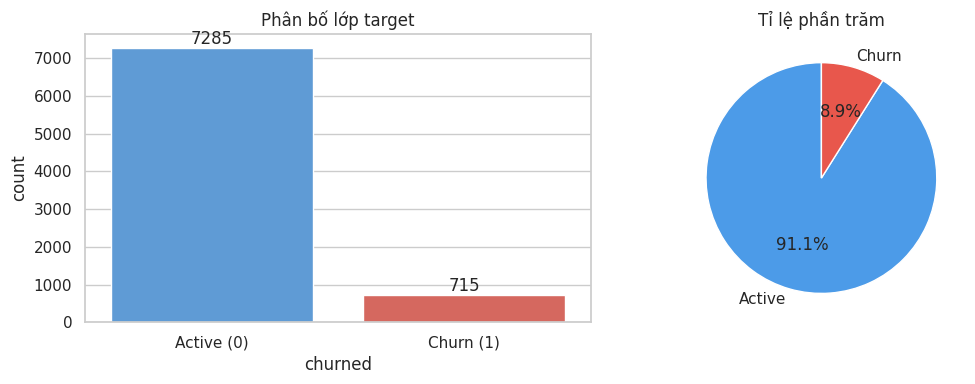

Accuracy nếu luôn đoán 'Active' = 0.9106  -> accuracy đơn thuần KHÔNG đủ để đánh giá mô hình


In [6]:
TARGET = 'churned'

counts = df[TARGET].value_counts().sort_index()
ratio = counts / counts.sum() * 100
print(pd.DataFrame({'count': counts, 'percent (%)': ratio.round(2)}).rename(index={0: 'Active (0)', 1: 'Churn (1)'}))
print(f"\nImbalance ratio (Active : Churn) = {counts[0] / counts[1]:.1f} : 1")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x=TARGET, data=df, palette=['#4C9BE8', '#E8574C'], ax=ax[0])
ax[0].set_xticklabels(['Active (0)', 'Churn (1)'])
ax[0].set_title('Phân bố lớp target')
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha='center', va='bottom')
ax[1].pie(counts, labels=['Active', 'Churn'], autopct='%1.1f%%', colors=['#4C9BE8', '#E8574C'], startangle=90)
ax[1].set_title('Tỉ lệ phần trăm')
plt.tight_layout()
plt.show()

# "Baseline ngây thơ": luôn đoán Active
print(f"Accuracy nếu luôn đoán 'Active' = {counts[0] / counts.sum():.4f}  -> accuracy đơn thuần KHÔNG đủ để đánh giá mô hình")

## 3. Tiền xử lý dữ liệu
- Bỏ `customer_id` (định danh, không mang thông tin dự đoán).
- Chuyển `registration_date` thành `tenure_days` (số ngày từ lúc đăng ký đến ngày mới nhất trong dữ liệu).
- Numeric → `StandardScaler` (cần cho Logistic Regression); Categorical → `OneHotEncoder`.
- Chia train/test **80/20 có `stratify=y`** để giữ nguyên tỉ lệ churn ở cả hai tập.
- Toàn bộ tiền xử lý nằm trong `Pipeline` để **tránh data leakage**.

In [7]:
data = df.copy()
data['registration_date'] = pd.to_datetime(data['registration_date'], errors='coerce')
ref_date = data['registration_date'].max()
data['tenure_days'] = (ref_date - data['registration_date']).dt.days
data['tenure_days'] = data['tenure_days'].fillna(data['tenure_days'].median())

X = data.drop(columns=[TARGET, 'customer_id', 'registration_date'])
y = data[TARGET]

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()
print('Numeric    :', num_cols)
print('Categorical:', cat_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"\nTrain: {X_train.shape}  | churn rate = {y_train.mean():.4f}")
print(f"Test : {X_test.shape}  | churn rate = {y_test.mean():.4f}")

def make_preprocessor(scale=True):
    num_tf = StandardScaler() if scale else 'passthrough'
    return ColumnTransformer([
        ('num', num_tf, num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ])

Numeric    : ['age', 'total_orders', 'total_spend_usd', 'avg_order_value_usd', 'days_since_last_purchase', 'reviews_given', 'avg_review_score', 'returns_made', 'wishlist_items', 'newsletter_subscribed', 'tenure_days']
Categorical: ['country', 'gender', 'membership_tier', 'preferred_category', 'preferred_device', 'preferred_payment_method', 'acquisition_channel']

Train: (6400, 18)  | churn rate = 0.0894
Test : (1600, 18)  | churn rate = 0.0894


## 4. Huấn luyện & so sánh mô hình
Huấn luyện 4 mô hình để thấy rõ tác động của xử lý imbalance:

| Mô hình | class_weight |
|---|---|
| Logistic Regression (baseline) | không |
| Logistic Regression | `'balanced'` |
| Decision Tree (baseline) | không |
| Decision Tree | `'balanced'` |

Decision Tree được giới hạn độ sâu (`max_depth`, `min_samples_leaf`) bằng `GridSearchCV` (CV 5-fold, scoring = **F1 của lớp Churn**) để tránh overfitting. Logistic Regression cũng tinh chỉnh `C`.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def build_lr(class_weight):
    pipe = Pipeline([
        ('prep', make_preprocessor(scale=True)),
        ('clf', LogisticRegression(class_weight=class_weight, max_iter=2000, random_state=RANDOM_STATE))
    ])
    grid = {'clf__C': [0.01, 0.1, 1, 10]}
    return GridSearchCV(pipe, grid, scoring='f1', cv=cv, n_jobs=-1)

def build_dt(class_weight):
    pipe = Pipeline([
        ('prep', make_preprocessor(scale=False)),
        ('clf', DecisionTreeClassifier(class_weight=class_weight, random_state=RANDOM_STATE))
    ])
    grid = {'clf__max_depth': [3, 4, 5, 6, 8],
            'clf__min_samples_leaf': [10, 20, 50]}
    return GridSearchCV(pipe, grid, scoring='f1', cv=cv, n_jobs=-1)

models = {
    'LogReg (no weight)':       build_lr(None),
    'LogReg (balanced)':        build_lr('balanced'),
    'DecisionTree (no weight)': build_dt(None),
    'DecisionTree (balanced)':  build_dt('balanced'),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    print(f"{name:26s} | best params: {m.best_params_} | CV F1 (Churn) = {m.best_score_:.4f}")

LogReg (no weight)         | best params: {'clf__C': 1} | CV F1 (Churn) = 0.0335
LogReg (balanced)          | best params: {'clf__C': 0.01} | CV F1 (Churn) = 0.2159
DecisionTree (no weight)   | best params: {'clf__max_depth': 4, 'clf__min_samples_leaf': 50} | CV F1 (Churn) = 0.1905
DecisionTree (balanced)    | best params: {'clf__max_depth': 3, 'clf__min_samples_leaf': 10} | CV F1 (Churn) = 0.3993


## 5. Đánh giá: Classification Report & Confusion Matrix
Với mỗi mô hình in `classification_report` (Precision, Recall, F1, Accuracy) và vẽ Confusion Matrix heatmap (số lượng + phần trăm theo hàng).

LogReg (no weight)
              precision    recall  f1-score   support

  Active (0)     0.9127    0.9979    0.9534      1457
   Churn (1)     0.5714    0.0280    0.0533       143

    accuracy                         0.9113      1600
   macro avg     0.7421    0.5130    0.5034      1600
weighted avg     0.8822    0.9113    0.8730      1600



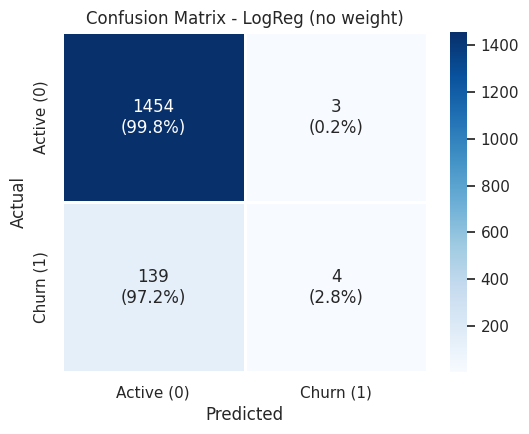

LogReg (balanced)
              precision    recall  f1-score   support

  Active (0)     0.9498    0.6616    0.7799      1457
   Churn (1)     0.1573    0.6434    0.2527       143

    accuracy                         0.6600      1600
   macro avg     0.5535    0.6525    0.5163      1600
weighted avg     0.8789    0.6600    0.7328      1600



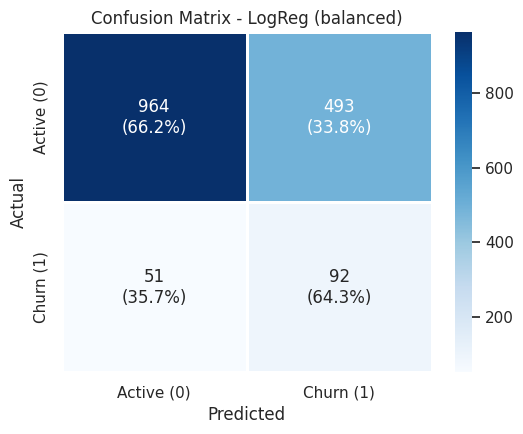

DecisionTree (no weight)
              precision    recall  f1-score   support

  Active (0)     0.9248    0.9876    0.9552      1457
   Churn (1)     0.5909    0.1818    0.2781       143

    accuracy                         0.9156      1600
   macro avg     0.7579    0.5847    0.6166      1600
weighted avg     0.8950    0.9156    0.8947      1600



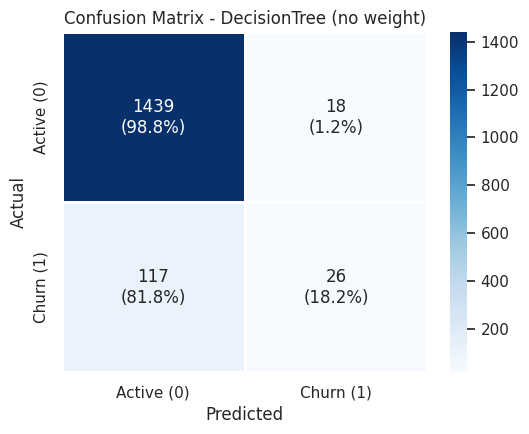

DecisionTree (balanced)
              precision    recall  f1-score   support

  Active (0)     0.9520    0.8840    0.9167      1457
   Churn (1)     0.3158    0.5455    0.4000       143

    accuracy                         0.8538      1600
   macro avg     0.6339    0.7147    0.6584      1600
weighted avg     0.8951    0.8538    0.8705      1600



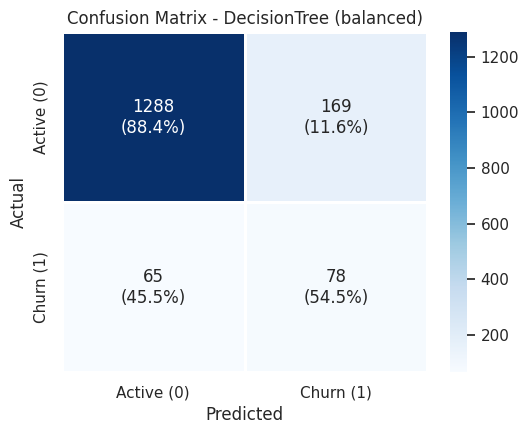

In [9]:
class_names = ['Active (0)', 'Churn (1)']
results = []
preds = {}

def evaluate(name, model):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    preds[name] = (y_pred, y_proba)

    print('=' * 70)
    print(f'{name}')
    print('=' * 70)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

    cm = confusion_matrix(y_test, y_pred)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f'{cm[i, j]}\n({cm_pct[i, j]:.1f}%)' for j in range(2)] for i in range(2)])

    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=True,
                xticklabels=class_names, yticklabels=class_names, linewidths=1, linecolor='white')
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (Churn)': precision_score(y_test, y_pred, zero_division=0),
        'Recall (Churn)': recall_score(y_test, y_pred),
        'F1 (Churn)': f1_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, average='macro'),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
    })

for name, m in models.items():
    evaluate(name, m)

## 6. Bảng so sánh tổng hợp

,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),Macro F1,ROC-AUC
Model,,,,,,
LogReg (no weight),0.9112,0.5714,0.0280,0.0533,0.5034,0.6965
LogReg (balanced),0.6600,0.1573,0.6434,0.2527,0.5163,0.6974
DecisionTree (no weight),0.9156,0.5909,0.1818,0.2781,0.6166,0.7224
DecisionTree (balanced),0.8538,0.3158,0.5455,0.4000,0.6584,0.7022


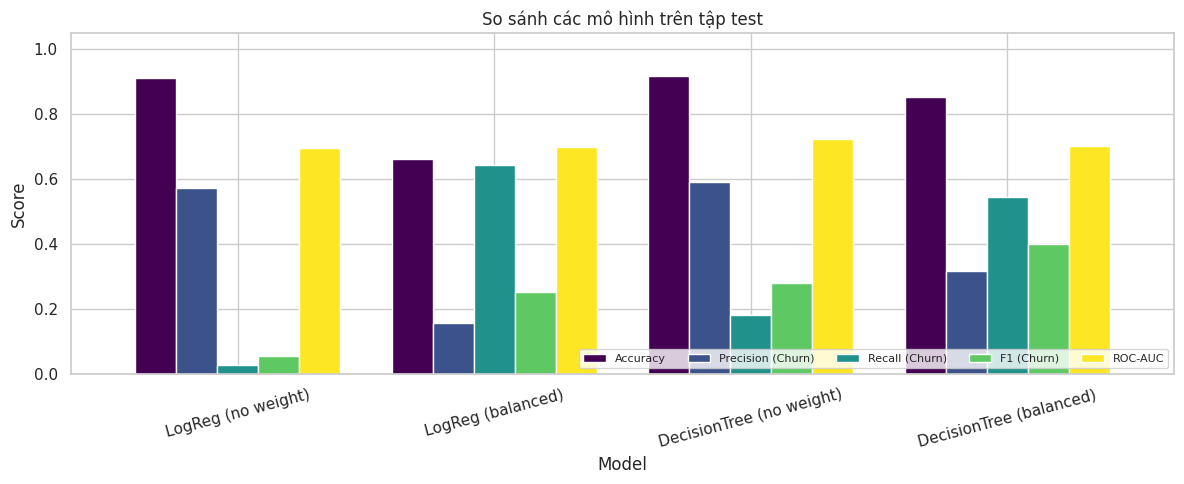

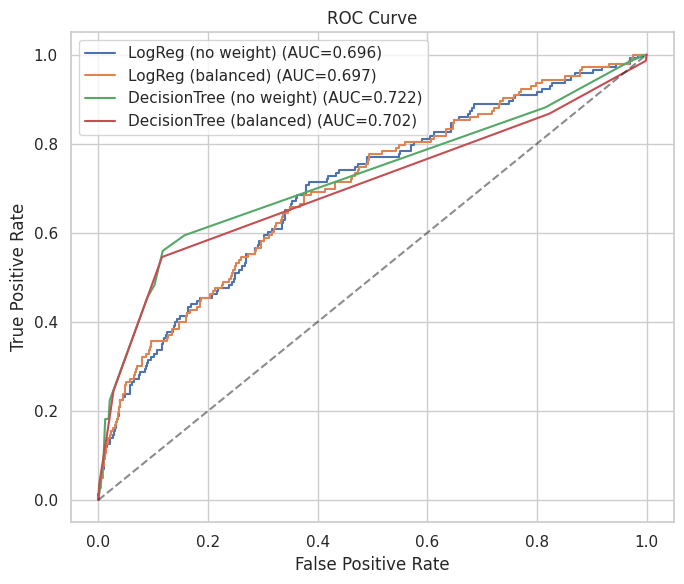

In [10]:
res_df = pd.DataFrame(results).set_index('Model').round(4)
display(res_df.style.background_gradient(cmap='YlGn', axis=0).format('{:.4f}'))

ax = res_df[['Accuracy', 'Precision (Churn)', 'Recall (Churn)', 'F1 (Churn)', 'ROC-AUC']].plot(
    kind='bar', figsize=(12, 5), width=0.8, colormap='viridis')
plt.title('So sánh các mô hình trên tập test')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc='lower right', ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

# ROC curves
plt.figure(figsize=(7, 6))
for name, (_, proba) in preds.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve'); plt.legend(); plt.tight_layout(); plt.show()

## 7. Giải thích mô hình (Feature importance)

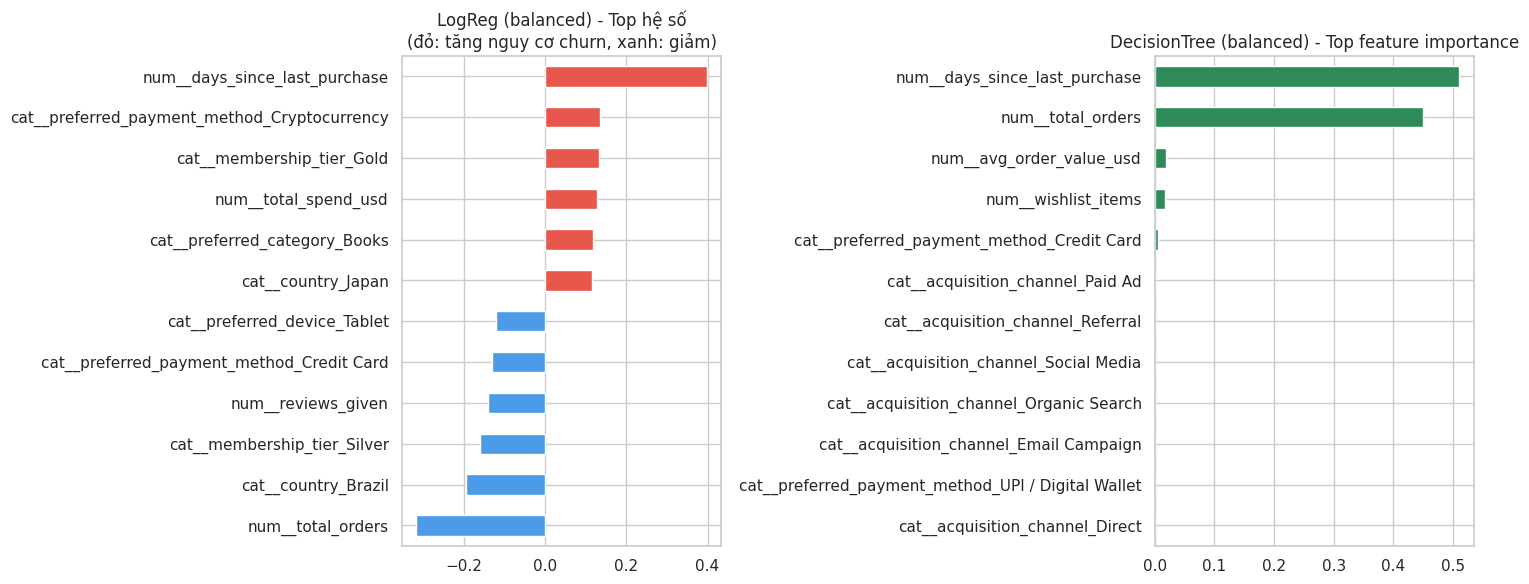

In [11]:
def feature_names(model):
    return model.best_estimator_.named_steps['prep'].get_feature_names_out()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Logistic Regression (balanced): hệ số
lr = models['LogReg (balanced)']
coef = pd.Series(lr.best_estimator_.named_steps['clf'].coef_[0], index=feature_names(lr))
top = coef.reindex(coef.abs().sort_values(ascending=False).head(12).index).sort_values()
top.plot(kind='barh', ax=axes[0], color=np.where(top > 0, '#E8574C', '#4C9BE8'))
axes[0].set_title('LogReg (balanced) - Top hệ số\n(đỏ: tăng nguy cơ churn, xanh: giảm)')

# Decision Tree (balanced): importance
dt = models['DecisionTree (balanced)']
imp = pd.Series(dt.best_estimator_.named_steps['clf'].feature_importances_, index=feature_names(dt))
imp.sort_values().tail(12).plot(kind='barh', ax=axes[1], color='#2E8B57')
axes[1].set_title('DecisionTree (balanced) - Top feature importance')

plt.tight_layout()
plt.show()

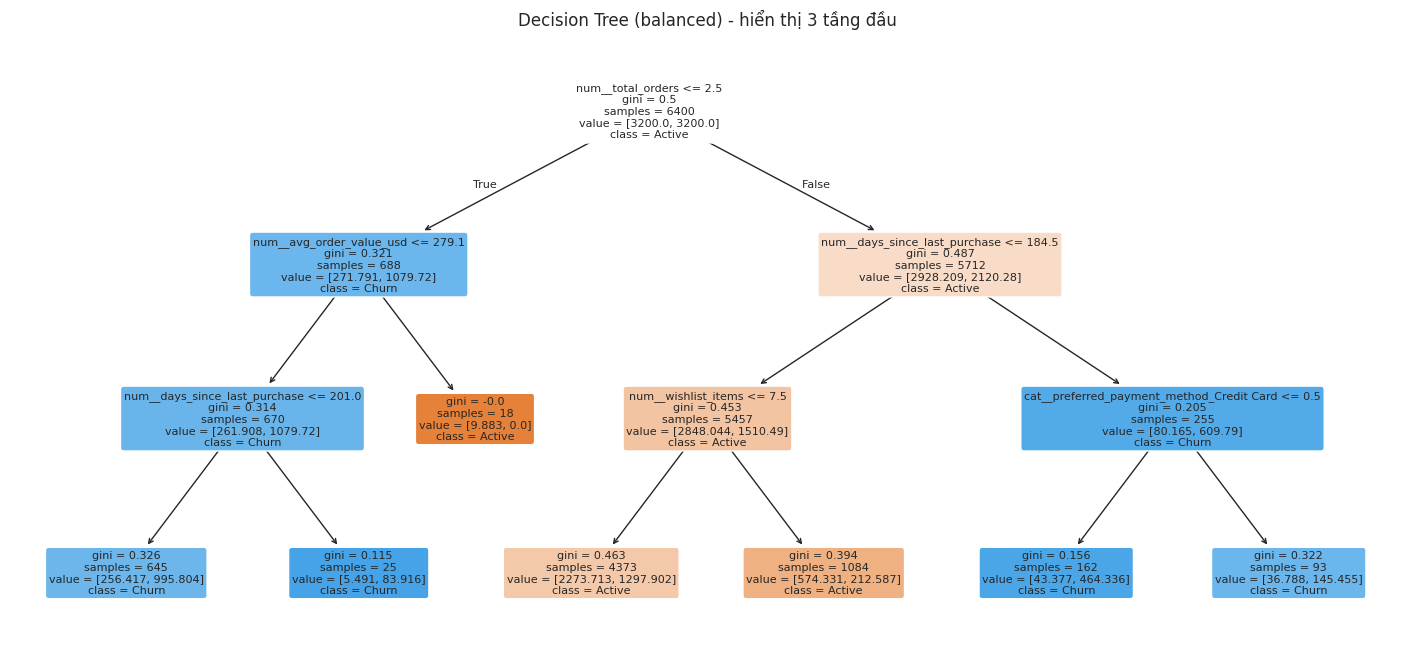

In [12]:
# Hình dạng cây quyết định (balanced) - 3 tầng đầu để dễ đọc
best_tree = dt.best_estimator_.named_steps['clf']
plt.figure(figsize=(18, 8))
plot_tree(best_tree, feature_names=list(feature_names(dt)), class_names=['Active', 'Churn'],
          filled=True, rounded=True, max_depth=3, fontsize=8)
plt.title('Decision Tree (balanced) - hiển thị 3 tầng đầu')
plt.show()

## 8. Nhận xét & kết luận
- **Imbalance:** lớp Churn chỉ chiếm ~9% → mô hình không xử lý imbalance thường đạt accuracy cao (~91%) nhưng **Recall của lớp Churn thấp** (bỏ sót nhiều khách sắp rời đi). Xem Confusion Matrix của các mô hình "no weight" để thấy số lượng False Negative.
- **`class_weight='balanced'`:** tăng Recall (và thường là F1) của lớp Churn, đổi lại Precision giảm và accuracy tổng có thể giảm nhẹ – đây là đánh đổi chấp nhận được vì **bỏ sót khách churn thường tốn kém hơn** so với gửi nhầm một ưu đãi giữ chân.
- **Logistic Regression vs Decision Tree:** Logistic Regression ổn định, dễ giải thích qua hệ số; Decision Tree bắt được quan hệ phi tuyến/tương tác và cho các luật dễ đọc nhưng dễ overfit nếu không giới hạn độ sâu. Hãy chọn mô hình có **F1/Recall (Churn) và ROC-AUC** tốt nhất ở bảng so sánh phía trên.
- **Lưu ý:** các feature hành vi như `days_since_last_purchase` thường là yếu tố dự báo churn mạnh nhất; cần cẩn trọng nếu nhãn `churned` được định nghĩa trực tiếp từ chính feature này (rủi ro leakage).
- **Hướng cải thiện:** thử SMOTE/under-sampling (thư viện `imbalanced-learn`), điều chỉnh ngưỡng quyết định (threshold) theo Precision–Recall, hoặc dùng Random Forest / Gradient Boosting.